In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

import warnings
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning
)

In [4]:
# Start with simple airline passenger dataset with a clear pattern
passenger_data = pd.read_csv("airline-passengers.csv")
print(passenger_data)

       month  total_passengers
0    1949-01               112
1    1949-02               118
2    1949-03               132
3    1949-04               129
4    1949-05               121
..       ...               ...
139  1960-08               606
140  1960-09               508
141  1960-10               461
142  1960-11               390
143  1960-12               432

[144 rows x 2 columns]


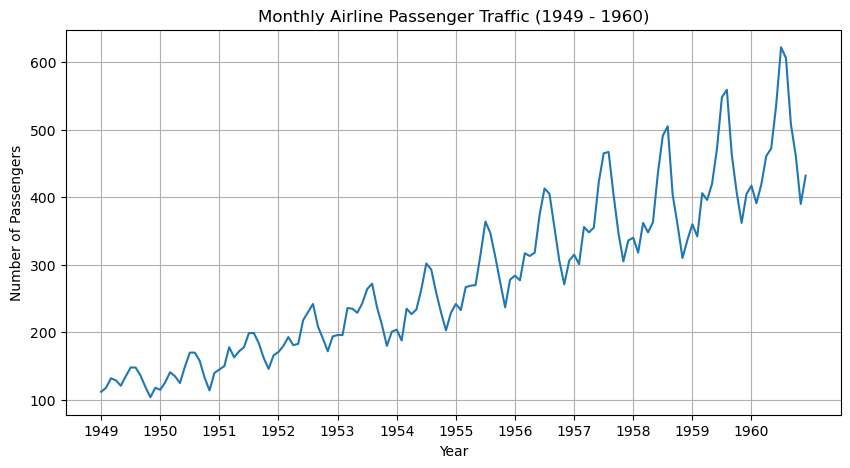

In [5]:
# Plot all the data to show the behavior over time
plt.figure(figsize=(10, 5))

plt.plot(passenger_data["month"], passenger_data["total_passengers"])
plt.xticks(range(0, 144, 12), range(1949, 1961))

plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.title("Monthly Airline Passenger Traffic (1949 - 1960)")
plt.grid(True)
plt.show()

## Following Previous Year's Lecture on Time-Forecasting

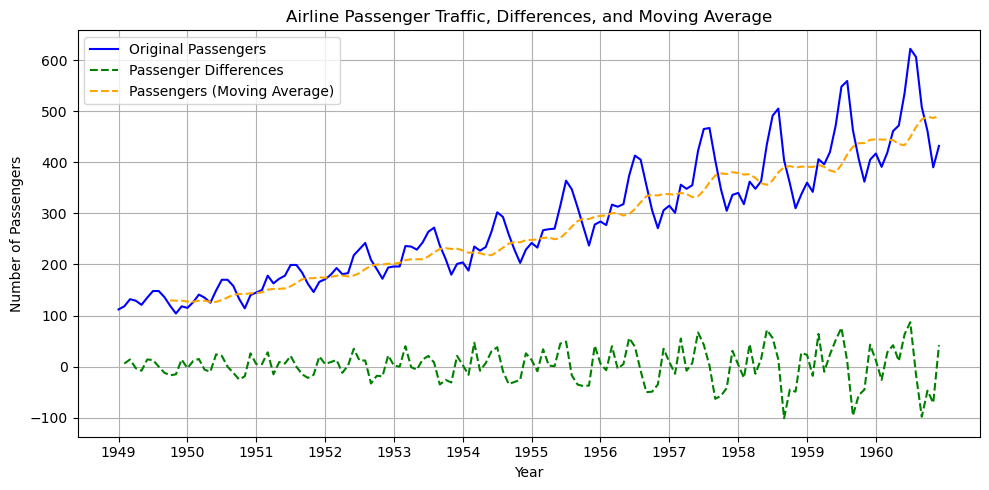

In [6]:
# Preprocess data into differences and moving averages

fig, ax = plt.subplots(figsize=(10, 5))

# Original Data
passenger_data.plot(
    x="month",
    y="total_passengers",
    ax=ax,
    label="Original Passengers",
    color="blue",
)

# Differences
passenger_data["total_passengers"].diff().iloc[1:].plot(
    ax=ax,
    label="Passenger Differences",
    color="green",
    linestyle="--"
)

# Moving average
_WINDOW_ = 10
passenger_data["total_passengers"].rolling(window=_WINDOW_).mean().iloc[(_WINDOW_ - 1):].plot(
    y="total_passengers",
    ax=ax,
    label="Passengers (Moving Average)",
    color="orange",
    linestyle="--"
)

ax.set_xticks(range(0, 144, 12))
ax.set_xticklabels(range(1949, 1961))

ax.set_xlabel("Year")
ax.set_ylabel("Number of Passengers")
ax.set_title("Airline Passenger Traffic, Differences, and Moving Average")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

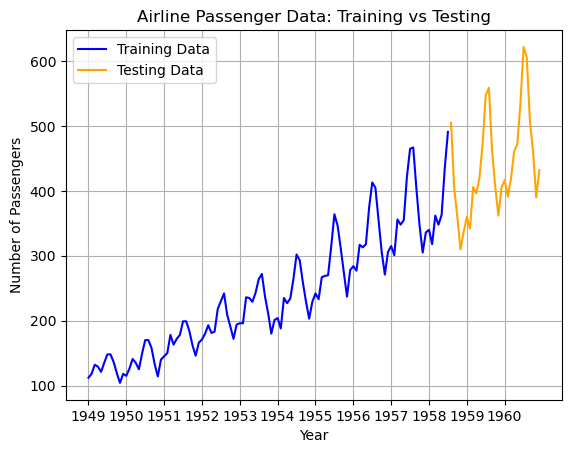

In [7]:
# Create train/test splits for the data
split_index = int(len(passenger_data) * 0.8)

train = passenger_data.iloc[:split_index]
test = passenger_data.iloc[split_index:]

fig, ax = plt.subplots()
ax.plot(train["month"], train["total_passengers"],
         label="Training Data", color="blue")

ax.plot(test["month"], test["total_passengers"],
         label="Testing Data", color="orange")

plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.title("Airline Passenger Data: Training vs Testing")

plt.xticks(range(0, 144, 12), range(1949, 1961))

plt.legend()
plt.grid(True)
plt.show()

In [8]:
# AR(p) model which assumes that current value of a time series
# can be predicted using previous values

# Convenience function to make lagged features (and target value) from a pandas series.
def make_lagged_features(series, max_lag=1):
    frame = pd.DataFrame({
            "target": series,
            **{f"lag_{i}": series.shift(i) for i in range(1, max_lag + 1)},
    })
    return frame.dropna()

# 10 previous values used for each target 
lagged_train = make_lagged_features(train["total_passengers"], max_lag=10)

# Seperate features and targets
X_train = lagged_train.drop("target", axis=1)
y_train = lagged_train["target"]

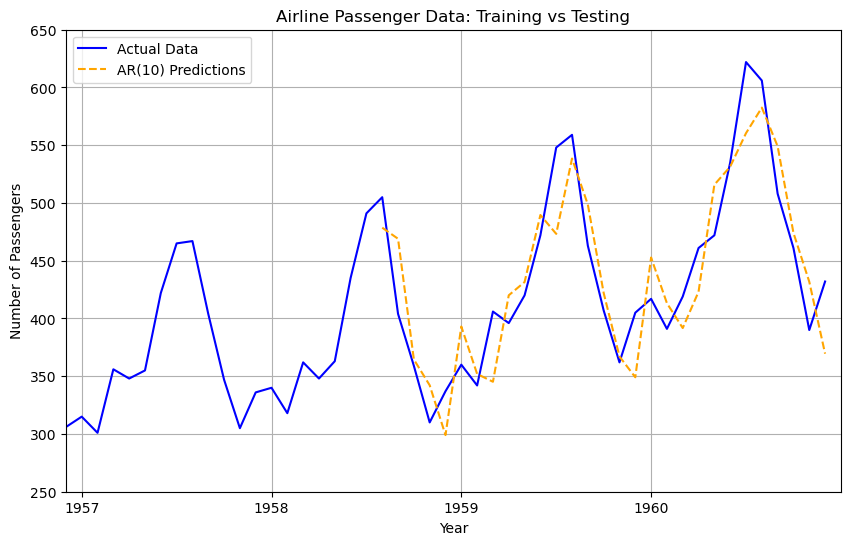

In [30]:
# Train linear regression model to predict the next value of time series
# based on the lagged features

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler

# Make linear regression model and train it
model = make_pipeline(
    MinMaxScaler(), LinearRegression()
)
model.fit(X_train, y_train)

# Combine last 10 training observations with testing data
combined = pd.concat([
    train["total_passengers"].iloc[-10:],
    test["total_passengers"]
])

lagged_test = make_lagged_features(combined, max_lag=10)
X_test = lagged_test.drop("target", axis=1)
y_test = lagged_test["target"]

predictions = model.predict(X_test)
predictions = pd.Series(predictions, index=y_test.index)

# Plot results
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    passenger_data["month"], 
    passenger_data["total_passengers"], 
    label="Actual Data", 
    color="blue"
)
ax.plot(
    test["month"],
    predictions, 
    label="AR(10) Predictions", 
    color="orange", 
    linestyle="--"
)

plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.title("Airline Passenger Data: Training vs Testing")
plt.xticks(range(0, 144, 12), range(1949, 1961))

ax.set_xlim(95, 144)
ax.set_ylim(250, 650)

plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Function to find MAE, RMSE, and MAPE of the forecast
def evaluate(prediction, actual_observation):
    mae = mean_absolute_error(actual_observation, prediction)
    rmse = root_mean_squared_error(actual_observation, prediction)
    mape = mean_absolute_percentage_error(actual_observation, prediction)
    
    print("Mean Absolute Error:", mae)
    print("Root Mean Squared Error", rmse)
    print("Mean Absolute Percentage Error:", mape * 100, "%")

evaluate(predictions, y_test)

Mean Absolute Error: 32.58603537413937
Root Mean Squared Error 37.932670744247034
Mean Absolute Percentage Error: 7.477451593376438 %



Trend: add  | Seasonal: add
Mean Absolute Error: 31.787038698656254
Root Mean Squared Error 39.25683906328257
Mean Absolute Percentage Error: 6.708089929059267 %

Trend: add  | Seasonal: mul
Mean Absolute Error: 21.960049894999244
Root Mean Squared Error 26.039411399250604
Mean Absolute Percentage Error: 4.818347629920091 %

Trend: mul  | Seasonal: add
Mean Absolute Error: 25.294264492195484
Root Mean Squared Error 32.17874588582556
Mean Absolute Percentage Error: 5.288250440160785 %

Trend: mul  | Seasonal: mul
Mean Absolute Error: 17.462049413959658
Root Mean Squared Error 21.336480670930044
Mean Absolute Percentage Error: 4.2563529973606045 %


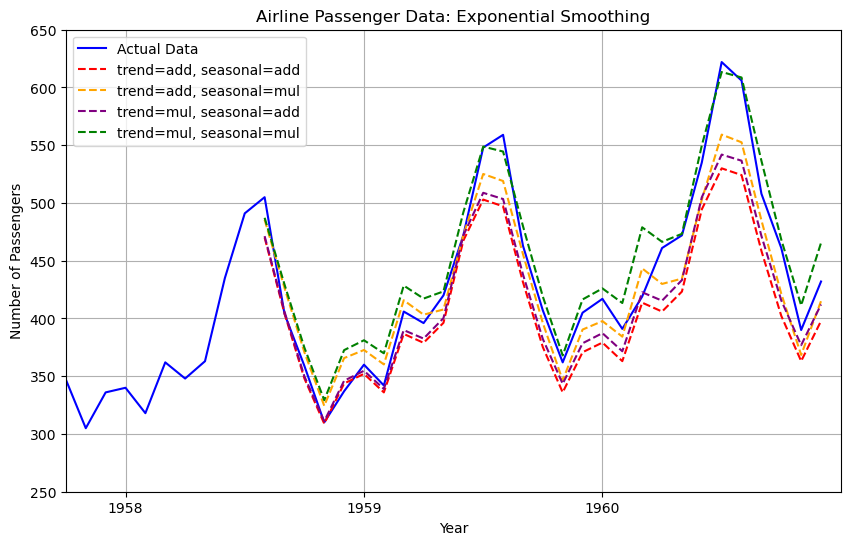

In [57]:
# Exponential Smoothing taking trends and seasonal behavior
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Trying 4 different models using additive/multiplicative trend/season and evaluate it
predictions = []
labels = []

for trend in ["add", "mul"]:
    for seasonal in ["add", "mul"]:
        model = ExponentialSmoothing(
            train["total_passengers"], 
            trend=trend, 
            seasonal=seasonal, 
            seasonal_periods=12,
        )
        prediction = model.fit().forecast(len(test))
        predictions.append(prediction)
        labels.append(f"trend={trend}, seasonal={seasonal}")
        print("\nTrend:", trend, " | Seasonal:", seasonal)
        evaluate(prediction, y_test)

# Plot results
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    passenger_data["month"], 
    passenger_data["total_passengers"], 
    label="Actual Data", 
    color="blue"
)

ax.plot(test["month"], predictions[0], label=labels[0], color="red", linestyle="--")
ax.plot(test["month"], predictions[1], label=labels[1], color="orange", linestyle="--")
ax.plot(test["month"], predictions[2], label=labels[2], color="purple", linestyle="--")
ax.plot(test["month"], predictions[3], label=labels[3], color="green", linestyle="--")

plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.title("Airline Passenger Data: Exponential Smoothing")
plt.xticks(range(0, 144, 12), range(1949, 1961))

ax.set_xlim(105, 144)
ax.set_ylim(250, 650)

plt.legend()
plt.grid(True)
plt.show()